In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

B = "../data/lake/bronze"
books     = pd.read_csv(f"{B}/books.csv")
customers = pd.read_csv(f"{B}/customers.csv")
orders    = pd.read_csv(f"{B}/orders.csv")
reviews   = pd.read_csv(f"{B}/reviews.csv")
print(len(books), len(customers), len(orders), len(reviews))

1000 515 3060 1200


In [2]:
def profile(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),                 # jenis data
        "non_null": df.notna().sum(),                   # berapa sel berisi
        "null_pct": (df.isna().mean() * 100).round(1),  # % sel kosong
        "unique": df.nunique(),                         # berapa nilai berbeza
        "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })

profile(customers)

,dtype,non_null,null_pct,unique,example
customer_id,object,515,0.0,500,C0256
full_name,object,515,0.0,90,Nurul binti Rahman
email,object,490,4.9,467,nurul.rahman61@gmail.com
phone,object,515,0.0,500,0199598487
mykad,object,515,0.0,500,990525-12-9195
state,object,515,0.0,22,Sabah
signup_date,object,515,0.0,385,2025-05-12


In [3]:
checks = {
    "customers: duplicate rows": customers.duplicated().sum(),
    "customers: missing email": customers["email"].isna().sum(),
    "orders: duplicate order_id": orders["order_id"].duplicated().sum(),
    "orders: quantity <= 0": (orders["quantity"] <= 0).sum(),
    "orders: date not YYYY-MM-DD": pd.to_datetime(
        orders["order_date"], format="%Y-%m-%d", errors="coerce").isna().sum(),
    "orders: unknown customer_id": (~orders["customer_id"].isin(customers["customer_id"])).sum(),
    "orders: unknown book_id": (~orders["book_id"].isin(books["book_id"])).sum(),
    "reviews: stars outside 1-5": (~reviews["stars"].between(1, 5)).sum(),
    "reviews: phone number in text": reviews["review_text"].str.contains(
        r"01\d-?\d{7}|\+601", na=False).sum(),
}
pd.Series(checks, name="issues").to_frame()

,issues
customers: duplicate rows,15
customers: missing email,25
orders: duplicate order_id,60
orders: quantity <= 0,29
orders: date not YYYY-MM-DD,94
orders: unknown customer_id,33
orders: unknown book_id,0
reviews: stars outside 1-5,0
reviews: phone number in text,21


In [8]:
books["price_gbp"] = books["price_raw"].str.replace(r"[^\d.]", "", regex=True).astype(float)
orders_ok = orders.assign(order_date=pd.to_datetime(
    orders["order_date"], format="%Y-%m-%d", errors="coerce"))

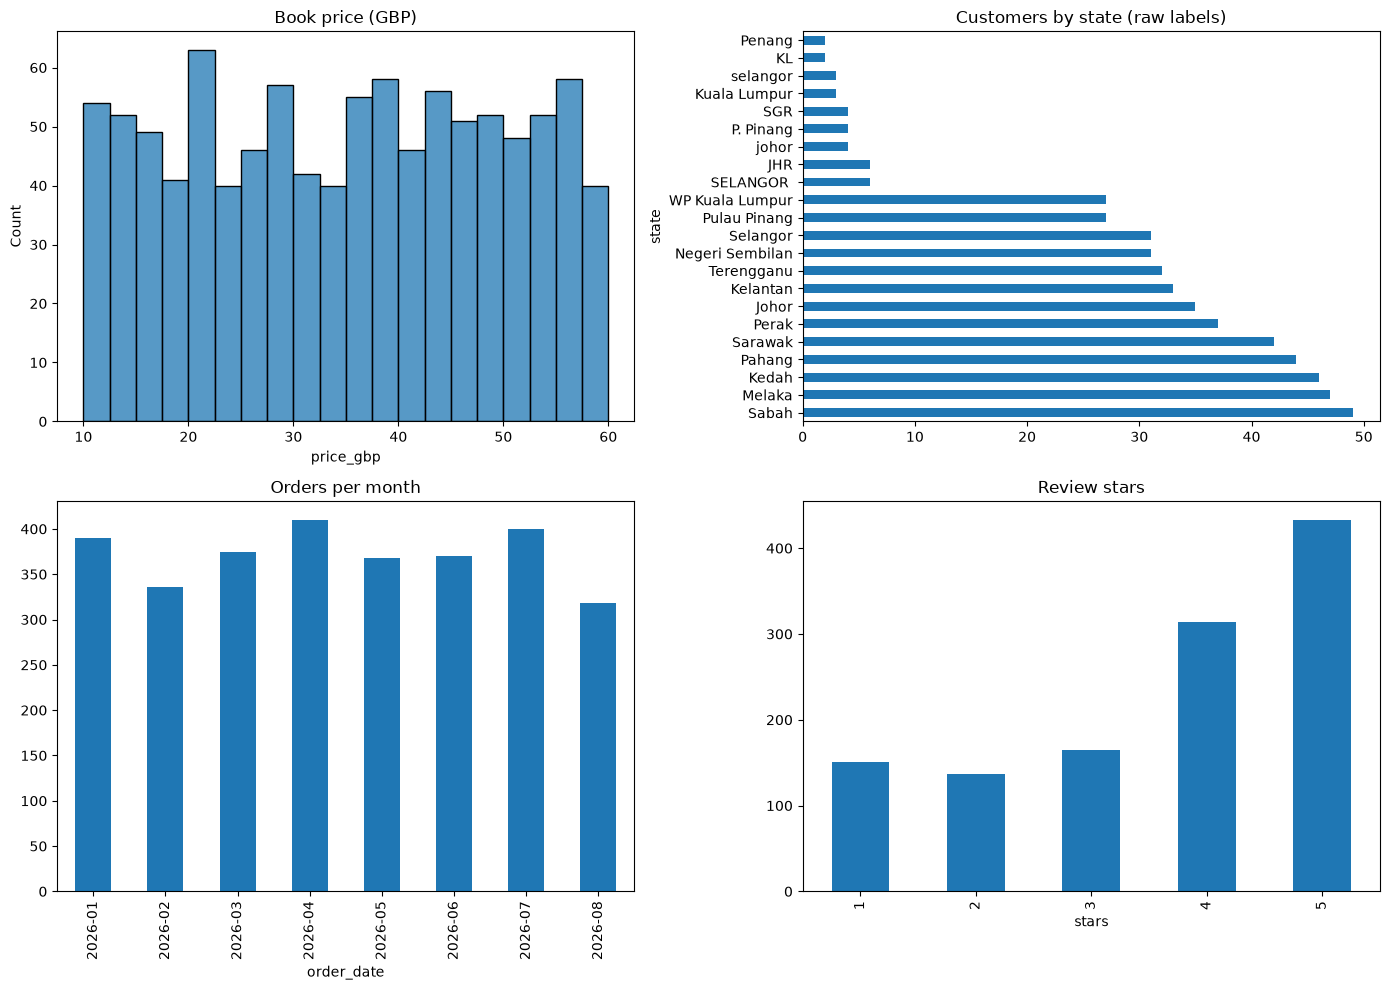

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(books["price_gbp"], bins=20, ax=axes[0, 0]).set_title("Book price (GBP)")
customers["state"].value_counts().plot.barh(ax=axes[0, 1], title="Customers by state (raw labels)")
orders_ok.groupby(orders_ok["order_date"].dt.to_period("M")).size().plot.bar(
    ax=axes[1, 0], title="Orders per month")
reviews["stars"].value_counts().sort_index().plot.bar(ax=axes[1, 1], title="Review stars")
plt.tight_layout()
plt.show()

In [10]:
print("state labels:", customers["state"].nunique())
print(customers["state"].value_counts())
print(customers.columns.tolist())

state labels: 22
state
Sabah              49
Melaka             47
Kedah              46
Pahang             44
Sarawak            42
Perak              37
Johor              35
Kelantan           33
Terengganu         32
Negeri Sembilan    31
Selangor           31
Pulau Pinang       27
WP Kuala Lumpur    27
 SELANGOR           6
JHR                 6
johor               4
P. Pinang           4
SGR                 4
Kuala Lumpur        3
selangor            3
KL                  2
Penang              2
Name: count, dtype: int64
['customer_id', 'full_name', 'email', 'phone', 'mykad', 'state', 'signup_date']


# Data Quality Report: KedaiBuku.my (Bronze Layer)

| Dimension | Table.column | Check | Issues found | Fix planned for Lab 5 |
|---|---|---|---|---|
| Uniqueness | customers | duplicate rows | 15 | Drop exact duplicates |
| Uniqueness | orders.order_id | duplicate order_id | 60 | Keep one row per order_id |
| Completeness | customers.email | missing values | 26 | Keep as null and flag; do not guess emails |
| Validity | orders.quantity | quantity ≤ 0 | 37 | Remove or flag invalid orders |
| Consistency | customers.state | several labels per state (e.g. SGR, selangor, SELANGOR) | 22 distinct labels for 13 states | Trim spaces and map all variants to one standard state name |
| Validity | orders.order_date | mixed date formats | 104 | Parse all dates and convert to YYYY-MM-DD |
| Integrity | orders.customer_id | unknown customer | 29 | Drop or flag orphan orders |
| Privacy | customers, reviews.review_text | personal data present (phone numbers in review text) | 30 reviews | Mask or remove personal data before analysis |

Checks that passed (0 issues): `orders.book_id` (unknown book) and `reviews.stars` (outside 1-5).

## 1. Personal data
Under PDPA 2010, the name, email, phone number and MyKad number in `customers` are personal data. The MyKad number is the most sensitive because it uniquely identifies a person and cannot easily be changed if leaked. `orders` and `reviews` are also personal data indirectly, because `customer_id` links them back to a person. Personal data also hides in free text: 30 reviews contain phone numbers in `review_text`, which a column-based check would miss.

## 2. Bias risk
Review stars lean heavily towards 4 and 5. If KedaiBuku used stars to decide which books to promote, it would favour books that already look popular, and real complaints would be under-represented. The ratings may also come only from customers who chose to leave a review, so they may not represent all buyers. Some states have few or no customers: Perlis, Labuan and Putrajaya do not appear at all, and Pulau Pinang is the smallest of the rest (19 under its main label, about 30 after merging variants such as "P. Pinang" and "Penang"). Their preferences and sales would be under-represented in any analysis.